# Stock Direction Classification (Up / Down)

After a few of these where I tried to predict actual prices, I wanted to switch framings. Regressing the next day's close is a hard problem and the metrics get dominated by the lag-1 baseline. Predicting **direction** — will tomorrow's close be higher or lower — is more honest about what's actually achievable. The ceiling is much lower (50% from a coin flip), but if I beat that consistently by even a couple of points after costs, that's interesting.

**Ticker:** SPY (S&P 500 ETF). Liquid, well-behaved, lots of history.

**Features:** rolling returns, rolling stds, RSI, MA crossovers — standard technical-analysis ingredients. Not because I think TA is magic, but because they're a reasonable hypothesis space for a momentum/mean-reversion classifier.

**Models:** logistic regression (interpretable baseline) and random forest (in case there's non-linear interaction).


In [1]:
# !pip install yfinance scikit-learn -q
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

np.random.seed(7)


In [2]:
spy = yf.download("SPY", period="10y", progress=False, auto_adjust=True)
spy = spy[["Close", "High", "Low", "Volume"]].dropna()
spy.columns = ["close", "high", "low", "volume"]
print(f"SPY: {len(spy)} rows  |  {spy.index.min().date()} -> {spy.index.max().date()}")
spy.tail(2)


SPY: 2513 rows  |  2016-05-16 -> 2026-05-13


,close,high,low,volume
Date,,,,
2026-05-12,738.179993,738.840027,731.830017,54185300
2026-05-13,742.309998,743.900024,735.469971,37500556


## Feature engineering

The target is `1` if tomorrow's close > today's close, else `0`. That makes this a tomorrow-vs-today decision, not a long-horizon call.


In [3]:
def rsi(close, period=14):
    delta = close.diff()
    up   = delta.clip(lower=0).rolling(period).mean()
    down = (-delta.clip(upper=0)).rolling(period).mean()
    rs = up / down.replace(0, np.nan)
    return 100 - 100 / (1 + rs)

df = spy.copy()
df["ret_1"]  = df["close"].pct_change()
df["ret_5"]  = df["close"].pct_change(5)
df["ret_20"] = df["close"].pct_change(20)

df["vol_5"]  = df["ret_1"].rolling(5).std()
df["vol_20"] = df["ret_1"].rolling(20).std()

df["ma_5_20"] = df["close"].rolling(5).mean() / df["close"].rolling(20).mean() - 1
df["ma_20_50"] = df["close"].rolling(20).mean() / df["close"].rolling(50).mean() - 1

df["rsi_14"] = rsi(df["close"], 14)

df["volume_z20"] = (df["volume"] - df["volume"].rolling(20).mean()) / df["volume"].rolling(20).std()
df["high_low_range"] = (df["high"] - df["low"]) / df["close"]

# target — does close go up tomorrow?
df["target"] = (df["close"].shift(-1) > df["close"]).astype(int)

feature_cols = ["ret_1", "ret_5", "ret_20", "vol_5", "vol_20",
                "ma_5_20", "ma_20_50", "rsi_14", "volume_z20", "high_low_range"]

df = df.dropna()
print(f"Samples after dropna: {len(df)}")
print(f"Class balance: up={df['target'].mean():.3f}  down={1 - df['target'].mean():.3f}")
# slight up bias is normal for SPY — equities drift up over decade-long windows


Samples after dropna: 2464
Class balance: up=0.554  down=0.446


## Chronological split + train

In [4]:
split = int(len(df) * 0.8)
X = df[feature_cols].values
y = df["target"].values
dates = df.index

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

lr = LogisticRegression(C=1.0, max_iter=1000).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=7).fit(X_train, y_train)

results = {}
for name, model, Xv in [("LogReg", lr, X_test_s), ("RandomForest", rf, X_test)]:
    pred  = model.predict(Xv)
    proba = model.predict_proba(Xv)[:, 1]
    results[name] = {
        "acc":  accuracy_score(y_test, pred),
        "auc":  roc_auc_score(y_test, proba),
        "pred": pred,
        "proba": proba,
    }
    print(f"{name:<14}  acc={results[name]['acc']:.3f}   AUC={results[name]['auc']:.3f}")

# coin-flip baseline + majority-class baseline
print(f"\nMajority-class accuracy: {max(y_test.mean(), 1 - y_test.mean()):.3f}")


LogReg          acc=0.560   AUC=0.464
RandomForest    acc=0.544   AUC=0.464

Majority-class accuracy: 0.576


Best by AUC: RandomForest

              precision    recall  f1-score   support

        down      0.300     0.057     0.096       209
          up      0.565     0.901     0.695       284

    accuracy                          0.544       493
   macro avg      0.433     0.479     0.396       493
weighted avg      0.453     0.544     0.441       493



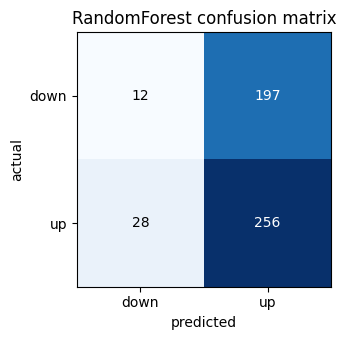

In [5]:
# Pick whichever model did better and dig in.
best = max(results, key=lambda k: results[k]["auc"])
print(f"Best by AUC: {best}\n")
print(classification_report(y_test, results[best]["pred"], target_names=["down", "up"], digits=3))

cm = confusion_matrix(y_test, results[best]["pred"])
fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center",
            color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["down", "up"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["down", "up"])
ax.set_xlabel("predicted"); ax.set_ylabel("actual")
ax.set_title(f"{best} confusion matrix")
plt.tight_layout()
plt.show()


## Feature importance (for the RF — easier to read than LR coefs after scaling)

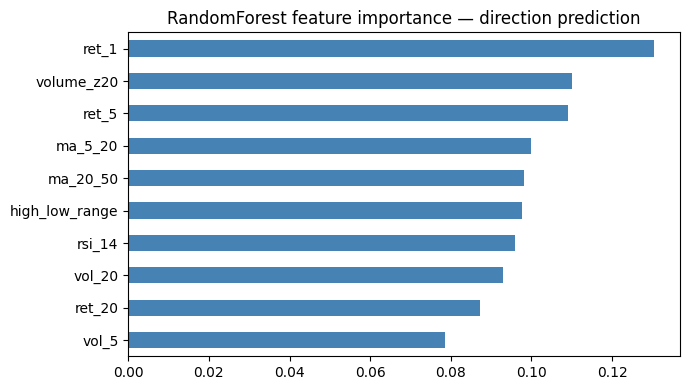

ret_1             0.130308
volume_z20        0.110161
ret_5             0.109067
ma_5_20           0.099776
ma_20_50          0.098169
high_low_range    0.097726
rsi_14            0.095953
vol_20            0.093041
ret_20            0.087199
vol_5             0.078601
dtype: float64


In [6]:
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_title("RandomForest feature importance — direction prediction")
plt.tight_layout()
plt.show()
print(imp.iloc[::-1])


## Reading this honestly

A few things to keep in mind:

- **Beating 52% is genuinely hard.** The literature on technical-feature direction classifiers tends to land in the 51-54% range out-of-sample after costs. If my number above is way higher, I'd suspect a leak rather than alpha.
- **Class imbalance matters.** SPY has more up days than down days over a 10-year window, so a "predict up every day" classifier will look ~53-55% accurate. The majority-class baseline above is the real bar to beat.
- **Costs aren't modeled.** A 51% direction edge on a 1-day signal sounds great until you subtract transaction costs and bid/ask spread, at which point it's usually a wash.
- **What I should actually believe:** the model probably learned some weak momentum/mean-reversion signal. If it didn't, the feature importances would look random; if it did, you'd expect `ret_5`, `ma_20_50`, and `rsi_14` to lead the chart.
